## Exercises

In [1]:
import os
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

from src.bigram_model import *

## Problem 1

train a trigram language model, i.e. take two characters as an input to predict the 3rd one. Feel free to use either counting or a neural net. Evaluate the loss; Did it improve over a bigram model?

In [2]:
words, char_to_idx, idx_to_char = prepare_data()

**Counting Trigram Model**

In [3]:
N = get_trigram_matrix(words, char_to_idx, smoothing=1.0)
loss = compute_trigram_matrix_loss(words, N, char_to_idx)
print(f'Trigram counting model loss {loss :.4f}')

Trigram counting model loss 2.0931


In [4]:
trigram_sampling(N, idx_to_char)

dey.
amelina.
un.
gunox.
mari.
pespzzgot.
srah.
hus.
mii.
bryahldtqcrease.


Bigram counting model loss on whole data = 2.4541 

Trigram counting model loss on whole data = 2.0931

**Neural Network Trigram Model**

In [5]:
xs, ys, zs = create_trigram_dataset(words, char_to_idx)
trigram_nn, _, _, _ = trigram_nn_train((xs, ys, zs), val_data=None, test_data=None, epochs=100, lr=50, reg=0.01)

Iteration 10: Train Loss 2.5439
Iteration 20: Train Loss 2.3964
Iteration 30: Train Loss 2.3449
Iteration 40: Train Loss 2.3189
Iteration 50: Train Loss 2.3035
Iteration 60: Train Loss 2.2933
Iteration 70: Train Loss 2.2860
Iteration 80: Train Loss 2.2805
Iteration 90: Train Loss 2.2764
Iteration 100: Train Loss 2.2731


In [6]:
sample_trigram_nn(trigram_nn, idx_to_char)

ni.
wahiyleo.
olishakygxurilani.
hazgirey.
gazeydish.
oth.
orier.
kattozan.
gun.
naylon.


Bigram NN model loss on whole data = 2.4906

Trigram NN model loss on whole data = 2.2731

Both the counting as well as the neural network trigram models perform better than the bigram versions.

1. The trigram sampling needs a second character other than the start. It is uniformly sampled from the 26 alphabets
2. The trigram neural network is of dimensions (54, 27) and the input is constructed by concatenating. I could have used addition and the model would have been smaller but concatenation somewhat preserves the relative ordering of the characters. Addition wont distinguish between `ab` and `ba` as the first two characters, concatenation will.

## Problem 2

split up the dataset randomly into 80% train set, 10% dev set, 10% test set. Train the bigram and trigram models only on the training set. Evaluate them on dev and test splits. What can you see?

In [7]:
train_words, val_words, test_words, char_to_idx, idx_to_char = prepare_data(split='default')
print(f'# Train words {len(train_words)}, # Val words {len(val_words)}, # Test words {len(test_words)}')

# Train words 25626, # Val words 3203, # Test words 3204


**Counting Trigram Model**

In [8]:
N = get_trigram_matrix(train_words, char_to_idx, smoothing=1.0)
train_loss = compute_trigram_matrix_loss(train_words, N, char_to_idx)
val_loss = compute_trigram_matrix_loss(val_words, N, char_to_idx)
test_loss = compute_trigram_matrix_loss(test_words, N, char_to_idx)
print(f'Trigram counting model losses: Train {train_loss :.4f}, Val {val_loss :.4f}, Test {test_loss :.4f}')

Trigram counting model losses: Train 2.0974, Val 2.1252, Test 2.1098


In [9]:
trigram_sampling(N, idx_to_char)

emsla.
zey.
xzpyqwesqygjah.
gari.
yvellah.
eilynzlian.
freena.
dee.
av.
qeus.


**Neural Network Trigram Model**

In [10]:
xs, ys, zs = create_trigram_dataset(train_words, char_to_idx)
xv, yv, zv = create_trigram_dataset(val_words, char_to_idx)
xt, yt, zt = create_trigram_dataset(test_words, char_to_idx)
trigram_nn, train_losses, val_losses, test_losses = trigram_nn_train((xs, ys, zs), 
                                                                     val_data=(xv, yv, zv), test_data=(xt, yt, zt), 
                                                                     epochs=100, lr=50, reg=0.01)

Iteration 10: Train Loss 2.4932 Val Loss 2.5235 Test Loss 2.4932
Iteration 20: Train Loss 2.3705 Val Loss 2.3943 Test Loss 2.3705
Iteration 30: Train Loss 2.3241 Val Loss 2.3453 Test Loss 2.3241
Iteration 40: Train Loss 2.2997 Val Loss 2.3196 Test Loss 2.2997
Iteration 50: Train Loss 2.2852 Val Loss 2.3042 Test Loss 2.2852
Iteration 60: Train Loss 2.2759 Val Loss 2.2943 Test Loss 2.2759
Iteration 70: Train Loss 2.2694 Val Loss 2.2875 Test Loss 2.2694
Iteration 80: Train Loss 2.2647 Val Loss 2.2824 Test Loss 2.2647
Iteration 90: Train Loss 2.2612 Val Loss 2.2786 Test Loss 2.2612
Iteration 100: Train Loss 2.2584 Val Loss 2.2756 Test Loss 2.2584


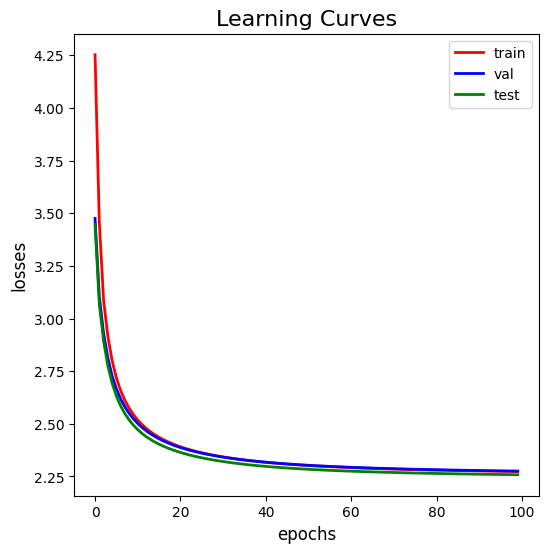

In [11]:
plot_nn_losses(train_losses, val_losses=val_losses, test_losses=test_losses)

In [12]:
sample_trigram_nn(trigram_nn, idx_to_char)

marlenn.
fekrta.
wa.
doleh.
zee.
uyn.
railenn.
yosan.
ph.
piel.


After splitting the losses are somewhat lower. 

*Even though there is no leakage between train and test data as I can see from my code, still the train and test losses are the same for the neural network trigram model. Why is this happening? If there were a leakage, then these losses for the counting model would also be the same, isnt it?*

## Problem 3

use the dev set to tune the strength of smoothing (or regularization) for the trigram model - i.e. try many possibilities and see which one works best based on the dev set loss. What patterns can you see in the train and dev set loss as you tune this strength? Take the best setting of the smoothing and evaluate on the test set once and at the end. How good of a loss do you achieve?

**Counting Trigram Model**

In [13]:
smooths = [0.1, 1.0, 2.0, 5.0, 10.0, 20.0, 50.0, 100.0]

for smooth in smooths:
    N = get_trigram_matrix(train_words, char_to_idx, smoothing=smooth)
    train_loss = compute_trigram_matrix_loss(train_words, N, char_to_idx)
    val_loss = compute_trigram_matrix_loss(val_words, N, char_to_idx)
    test_loss = compute_trigram_matrix_loss(test_words, N, char_to_idx)
    print(f'Smoothing {smooth}: Train {train_loss :.4f}, Val {val_loss :.4f}, Test {test_loss :.4f}')

Smoothing 0.1: Train 2.0647, Val 2.1079, Test 2.0960
Smoothing 1.0: Train 2.0974, Val 2.1252, Test 2.1098
Smoothing 2.0: Train 2.1246, Val 2.1475, Test 2.1312
Smoothing 5.0: Train 2.1865, Val 2.2034, Test 2.1858
Smoothing 10.0: Train 2.2613, Val 2.2742, Test 2.2562
Smoothing 20.0: Train 2.3663, Val 2.3759, Test 2.3579
Smoothing 50.0: Train 2.5508, Val 2.5572, Test 2.5408
Smoothing 100.0: Train 2.7128, Val 2.7176, Test 2.7034


As smoothing increases, the probabilities approach unifrom values and the losses increase. Best smoothing is at 0.1 with lowest train, val and test losses.

**Neural Network Trigram Model**

In [14]:
regs = [0.01, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0]

for reg in regs:
    trigram_nn, train_losses, val_losses, test_losses = trigram_nn_train((xs, ys, zs), 
                                                                     val_data=(xv, yv, zv), test_data=(xt, yt, zt), 
                                                                     epochs=100, lr=50, reg=reg, verbose=False)
    print(f'Regularization {reg}: Train {train_losses[-1] :.4f}, Val {val_losses[-1] :.4f}, Test {test_losses[-1] :.4f}')

Regularization 0.01: Train 2.2741, Val 2.2744, Test 2.2597
Regularization 0.1: Train 2.3301, Val 2.3319, Test 2.3161
Regularization 0.2: Train 2.3682, Val 2.3704, Test 2.3547
Regularization 0.5: Train 2.4535, Val 2.4561, Test 2.4406
Regularization 1.0: Train 2.5465, Val 2.5492, Test 2.5344
Regularization 2.0: Train 2.6630, Val 2.6661, Test 2.6524
Regularization 5.0: Train 2.8435, Val 2.8469, Test 2.8358
Regularization 10.0: Train 2.9880, Val 2.9919, Test 2.9858


Same observation as the counting model. Losses increase with regularization strength in the chosen range. Best regularization strength is 0.01 with minimum train, test, and val losses. 

*Can we derive a one-to-one correspondence between smoothing and regularization mathematically?*

## Problem 4

we saw that our 1-hot vectors merely select a row of W, so producing these vectors explicitly feels wasteful. Can you delete our use of F.one_hot in favor of simply indexing into rows of W?

In [15]:
def bigram_nn_train_1(train_data, val_data=None, test_data=None, epochs=100, lr=50, reg=0.01, verbose=True):
    W = torch.randn((27, 27), generator=g, requires_grad=True) 
    xs, ys = train_data
    train_losses, test_losses, val_losses = [], [], []

    # training loop
    for i in range(epochs):
        # forward pass with softmax activation
        X1 = W[xs, :]
        Xhat = X1.exp()
        probs = Xhat/Xhat.sum(dim=1, keepdims=True)

        # loss computation with regularization 
        loss = -probs[torch.arange(xs.shape[0]), ys].log().mean() + reg * (W ** 2).mean()
        train_losses.append(loss.item())

        # backpropagation
        W.grad = None # zero out the grads
        loss.backward()
        W.data -= lr * W.grad
        
        # if val data is present
        if val_data:
            xv, yv = val_data
            X1 = W[xv, :]
            Xhat = X1.exp()
            probs = Xhat/Xhat.sum(dim=1, keepdims=True)
            loss = -probs[torch.arange(xv.shape[0]), yv].log().mean() + reg * (W ** 2).mean()
            val_loss = loss.item()
            val_losses.append(val_loss)
        else:
            val_loss = 0.0
            
        # if test data is present
        if test_data:
            xt, yt = test_data
            X1 = W[xt, :]
            Xhat = X1.exp()
            probs = Xhat/Xhat.sum(dim=1, keepdims=True)
            loss = -probs[torch.arange(xt.shape[0]), yt].log().mean() + reg * (W ** 2).mean()
            test_loss = loss.item()
            test_losses.append(test_loss)
        else:
            test_loss = 0.0

        if (i+1)%10 == 0 and verbose:
            print_str = f'Iteration {i+1}: Train Loss {loss :.4f}'
            if val_data and test_data:
                print_str += f' Val Loss {val_loss :.4f} Test Loss {test_loss :.4f}'
            print(print_str)
    return W, train_losses, val_losses, test_losses

In [16]:
def sample_bigram_nn_1(bigram_nn, idx_to_char, num_words=10):
    for i in range(num_words):
        out = []
        idx = 0
        while True:
            X1 = bigram_nn[idx, :]  #this results in a 1D tensor with 1 dimension only  
            Xhat = X1.exp()
            probs = Xhat/Xhat.sum(dim=0, keepdims=True)  #so we are usign 0 here
            idx = torch.multinomial(probs, num_samples=1, replacement=True, generator=g).item()
            out.append(idx_to_char[idx])
            if idx == 0:
                break
        print(''.join(out))
    return

In [17]:
xs, ys = create_bigram_dataset(train_words, char_to_idx)
xv, yv = create_bigram_dataset(val_words, char_to_idx)
xt, yt = create_bigram_dataset(test_words, char_to_idx)

bigram_model, train_losses, val_losses, test_losses = bigram_nn_train_1((xs, ys), val_data=(xv, yv), test_data=(xt, yt), 
                                                                         epochs=100, lr=50, reg=reg, verbose=True)

Iteration 10: Train Loss 3.2066 Val Loss 3.2093 Test Loss 3.2066
Iteration 20: Train Loss 3.2059 Val Loss 3.2085 Test Loss 3.2059
Iteration 30: Train Loss 3.2058 Val Loss 3.2084 Test Loss 3.2058
Iteration 40: Train Loss 3.2058 Val Loss 3.2084 Test Loss 3.2058
Iteration 50: Train Loss 3.2058 Val Loss 3.2084 Test Loss 3.2058
Iteration 60: Train Loss 3.2058 Val Loss 3.2084 Test Loss 3.2058
Iteration 70: Train Loss 3.2058 Val Loss 3.2084 Test Loss 3.2058
Iteration 80: Train Loss 3.2058 Val Loss 3.2084 Test Loss 3.2058
Iteration 90: Train Loss 3.2058 Val Loss 3.2084 Test Loss 3.2058
Iteration 100: Train Loss 3.2058 Val Loss 3.2084 Test Loss 3.2058


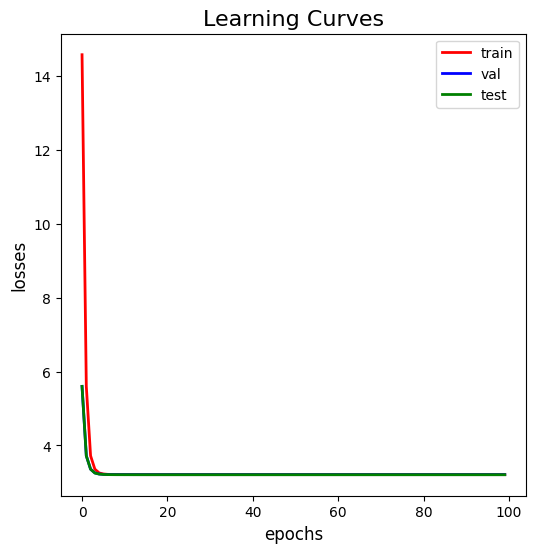

In [18]:
plot_nn_losses(train_losses, val_losses=val_losses, test_losses=test_losses)

In [19]:
sample_bigram_nn_1(bigram_model, idx_to_char)

nscdexbayjv.
yidhrtukixjfdzivbylapslkovrmwtxoaqfipnpriey.
uvdkehbhnygmlbgp.
axjliiqskpishhrspibwcuqjy.
mhbsxcxiamvnshafhsscdlwkshzpvmzgfinstlaxuktnewvrnehegyzmkjq.
czmnhypjqmdyqvksuhhsfvyhomzosnetxmz.
fkkawffhmvwpmhbmdwesvmkehmn.
ajrknkvvokbwvsipsaylymaysrgraiwwl.
idahdofcgkjbuduzrasjauhlyfitladvsadqucrzzzmkpoumb.
tshztg.


*Even here while training the bigram model, the train and test losses are the same. Why?*

## Problem 5

look up and use F.cross_entropy instead. You should achieve the same result. Can you think of why we'd prefer to use F.cross_entropy instead?

In [20]:
def bigram_nn_train_2(train_data, val_data=None, test_data=None, epochs=100, lr=50, reg=0.01, verbose=True):
    W = torch.randn((27, 27), generator=g, requires_grad=True) 
    xs, ys = train_data
    train_losses, test_losses, val_losses = [], [], []

    # training loop
    for i in range(epochs):
        # forward pass with softmax activation
        X1 = W[xs, :]

        # loss computation with regularization 
        loss = F.cross_entropy(X1, ys) + reg * (W ** 2).mean()
        train_losses.append(loss.item())

        # backpropagation
        W.grad = None # zero out the grads
        loss.backward()
        W.data -= lr * W.grad
        
        # if val data is present
        if val_data:
            xv, yv = val_data
            X1 = W[xv, :]
            
            loss = F.cross_entropy(X1, yv) + reg * (W ** 2).mean()
            val_loss = loss.item()
            val_losses.append(val_loss)
        else:
            val_loss = 0.0
            
        # if test data is present
        if test_data:
            xt, yt = test_data
            X1 = W[xt, :]
            
            loss = F.cross_entropy(X1, yt) + reg * (W ** 2).mean()
            test_loss = loss.item()
            test_losses.append(test_loss)
        else:
            test_loss = 0.0

        if (i+1)%10 == 0 and verbose:
            print_str = f'Iteration {i+1}: Train Loss {loss :.4f}'
            if val_data and test_data:
                print_str += f' Val Loss {val_loss :.4f} Test Loss {test_loss :.4f}'
            print(print_str)
    return W, train_losses, val_losses, test_losses

In [21]:
bigram_model, train_losses, val_losses, test_losses = bigram_nn_train_2((xs, ys), val_data=(xv, yv), test_data=(xt, yt), 
                                                                         epochs=100, lr=50, reg=reg, verbose=True)

Iteration 10: Train Loss 3.2092 Val Loss 3.2122 Test Loss 3.2092
Iteration 20: Train Loss 3.2060 Val Loss 3.2088 Test Loss 3.2060
Iteration 30: Train Loss 3.2058 Val Loss 3.2085 Test Loss 3.2058
Iteration 40: Train Loss 3.2058 Val Loss 3.2084 Test Loss 3.2058
Iteration 50: Train Loss 3.2058 Val Loss 3.2084 Test Loss 3.2058
Iteration 60: Train Loss 3.2058 Val Loss 3.2084 Test Loss 3.2058
Iteration 70: Train Loss 3.2058 Val Loss 3.2084 Test Loss 3.2058
Iteration 80: Train Loss 3.2058 Val Loss 3.2084 Test Loss 3.2058
Iteration 90: Train Loss 3.2058 Val Loss 3.2084 Test Loss 3.2058
Iteration 100: Train Loss 3.2058 Val Loss 3.2084 Test Loss 3.2058


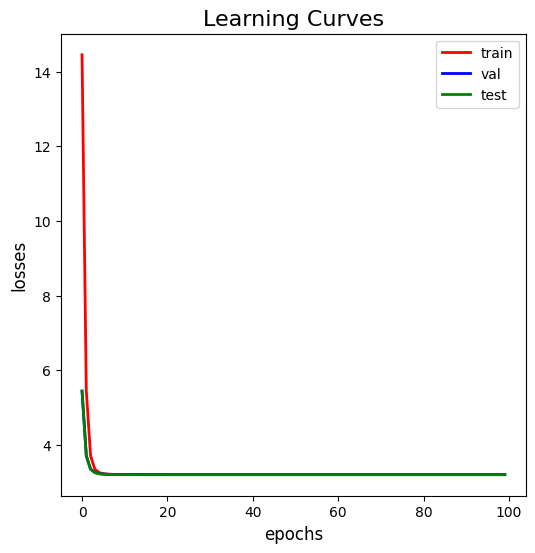

In [22]:
plot_nn_losses(train_losses, val_losses=val_losses, test_losses=test_losses)

In [23]:
sample_bigram_nn_1(bigram_model, idx_to_char)

qnzvwlysrfstn.
cjtjdovzqbj.
evnoxyugixtpwitwvfshloinuxzegaymvvos.
njkoesf.
nacryyoriqann.
mgn.
towpaaeiymbvcyeu.
jwudtggsrwljjbu.
pneijdk.
joeibfkmgvoxjygohqbhpekrevsngivjswfvpz.


I am getting the same final losses as the above.